# 🛡️ NSL-KDD Network Intrusion Detection: Comprehensive Exploratory Data Analysis (EDA)

## Executive Summary & Dataset Background
The **NSL-KDD** dataset is a globally recognized benchmark dataset for evaluating network intrusion detection systems (NIDS) and machine learning security classifiers. It is an enhanced, curated revision of the original **KDD Cup 1999** dataset, developed by Tavallaee et al. (2009) at the University of New Brunswick. 

The original KDD'99 dataset suffered from severe structural vulnerabilities, chief among them being enormous volumes of redundant records (~78% duplicate records in the training set and ~75% duplicate records in the test set). These duplicate records heavily biased machine learning algorithms toward frequent, repetitive attacks (such as simple SYN floods like *Neptune* and ICMP broadcast attacks like *Smurf*) while masking detection failure on sophisticated low-volume stealth attacks (*U2R* and *R2L*). NSL-KDD resolves these issues by eliminating redundant records, balancing the difficulty levels, and structuring distinct training (`KDDTrain+.csv`) and testing (`KDDTest+.csv`) sets.

---

## EDA Scope & Core Objectives
In this notebook, we perform an exhaustive exploratory data analysis covering all data quality dimensions, statistical distributions, security domain patterns, and potential modeling pitfalls:

1. **Shape & Dimensionality**: Dimensions of Train, Test, and Combined datasets, total records, memory footprint, data types.
2. **Feature Inventory & Semantics**: Complete taxonomy of all 41 predictor features categorized into Basic, Content, Time-based Traffic, and Host-based Traffic features.
3. **Missing Values & Structural Integrity**: Comprehensive null, infinite, and placeholder check.
4. **Duplicate Records & Overlaps**: Intra-dataset duplicates, feature-only duplicates, and cross-dataset (Train vs Test) overlaps.
5. **Class Counts & Binary Imbalance**: Normal vs Intrusion traffic distributions, imbalance ratios, and test set class inversion.
6. **Attack Types & 5-Class Categorization**: Mapping 38 distinct attack signatures into the 4 DARPA categories (**DoS**, **Probe**, **R2L**, **U2R**) and analyzing extreme minority classes.
7. **Novel / Zero-Day Attacks Analysis**: Discovery and quantification of 17 unseen attack types present exclusively in the test set.
8. **Feature Distributions & Descriptive Statistics**: Parametric and non-parametric summary statistics (mean, std, median, IQR, min, max, skewness, kurtosis) and multi-panel distribution plots.
9. **Feature vs Intrusion Patterns**: Empirical attack rates conditioned on protocol type, TCP flags, network services, and information-theoretic ranking (Mutual Information & ANOVA F-scores).
10. **Zero & Near-Zero Variance Check**: Detection of constant features (`num_outbound_cmds`) and near-zero variance features (`is_host_login`, `urgent`).
11. **Correlation Matrix & Multicollinearity**: Pearson correlation heatmap, multicollinear feature pairs ($|r| > 0.8$), and feature-target correlations.
12. **Boxplots & Visual Separation**: Comparative boxplots of continuous features across Normal vs Intrusion and across the 4 attack categories.
13. **Outliers & Extreme Values**: IQR and Z-score outlier detection, heavy-tailed distribution analysis (`src_bytes`, `dst_bytes`, `duration`), and domain interpretation.
14. **Data Leakage & Difficulty Score Evaluation**: Target/metadata leakage analysis of `difficulty_level` (column 42) and covariate shift between train and test.
15. **Actionable Roadmap for Preprocessing**: Direct mapping of EDA findings into concrete instructions for `02_preprocessing.ipynb` and subsequent modeling notebooks.


In [1]:
# Environment Configuration & Library Imports
import os
import sys
import warnings
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import f_classif, mutual_info_classif

# Ensure project root is in path
project_root = os.path.abspath('..') if os.path.exists('..') and 'dataset' in os.listdir('..') else os.path.abspath('.')
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Import reusable project modules
from src.data_loader import ATTACK_MAPPING, COLUMN_NAMES, FEATURE_GROUPS, load_nsl_kdd

# Configure visual styling
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.titlesize'] = 14

print("✅ Data Science environment initialized successfully.")
print(f"📦 Pandas: {pd.__version__} | NumPy: {np.__version__} | Seaborn: {sns.__version__}")


✅ Data Science environment initialized successfully.
📦 Pandas: 3.0.6 | NumPy: 2.5.4 | Seaborn: 0.13.2


In [2]:
# Dataset Ingestion using standardized schema
train_path = os.path.join(project_root, 'dataset', 'KDDTrain+.csv')
test_path = os.path.join(project_root, 'dataset', 'KDDTest+.csv')

train_df, test_df = load_nsl_kdd(train_path=train_path, test_path=test_path, add_derived_targets=True)

# Display sample records from the training set
print("Training Set Sample (First 3 Records):")
display(train_df.head(3))


Training Set Sample (First 3 Records):


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty_level,is_intrusion,attack_category
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.0,0.0,0.0,0.05,0.0,normal,20,0,Normal
1,0,udp,other,SF,146,0,0,0,0,0,...,0.88,0.0,0.0,0.0,0.00,0.0,normal,15,0,Normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19,1,DoS


## 1. Shape & Structural Overview

We first analyze the dimensional footprint, row counts, column counts, memory usage, and data types across the training, testing, and combined datasets.


In [3]:
# Dimensionality and Memory Footprint Analysis
combined_rows = len(train_df) + len(test_df)
train_mem_mb = train_df.memory_usage(deep=True).sum() / (1024 ** 2)
test_mem_mb = test_df.memory_usage(deep=True).sum() / (1024 ** 2)

shape_summary = pd.DataFrame([
    {
        'Dataset': 'KDDTrain+ (Train)',
        'Rows (Samples)': f"{train_df.shape[0]:,}",
        'Raw Columns': 43,
        'Derived Columns': 2,
        'Total Columns': train_df.shape[1],
        'Memory Footprint (MB)': f"{train_mem_mb:.2f} MB",
        'Split Percentage': f"{(len(train_df) / combined_rows) * 100:.2f}%"
    },
    {
        'Dataset': 'KDDTest+ (Test)',
        'Rows (Samples)': f"{test_df.shape[0]:,}",
        'Raw Columns': 43,
        'Derived Columns': 2,
        'Total Columns': test_df.shape[1],
        'Memory Footprint (MB)': f"{test_mem_mb:.2f} MB",
        'Split Percentage': f"{(len(test_df) / combined_rows) * 100:.2f}%"
    },
    {
        'Dataset': 'Combined (Total)',
        'Rows (Samples)': f"{combined_rows:,}",
        'Raw Columns': 43,
        'Derived Columns': 2,
        'Total Columns': train_df.shape[1],
        'Memory Footprint (MB)': f"{train_mem_mb + test_mem_mb:.2f} MB",
        'Split Percentage': "100.00%"
    }
])

display(shape_summary.style.hide(axis='index').set_caption("Table 1.1: Dataset Dimensions & Footprint"))

# Data types distribution
dtype_counts = train_df.dtypes.value_counts()
print(f"\nData Types Distribution in DataFrame:")
for dt, cnt in dtype_counts.items():
    print(f"  - {dt}: {cnt} columns")


Dataset,Rows (Samples),Raw Columns,Derived Columns,Total Columns,Memory Footprint (MB),Split Percentage
KDDTrain+ (Train),"125,973",43,2,45,70.50 MB,84.82%
KDDTest+ (Test),"22,543",43,2,45,12.62 MB,15.18%
Combined (Total),"148,516",43,2,45,83.13 MB,100.00%



Data Types Distribution in DataFrame:
  - int64: 25 columns
  - float64: 15 columns
  - str: 5 columns


## 2. Feature Inventory & Network Domain Categorization

The NSL-KDD dataset contains **41 predictor features**, **1 original attack label**, and **1 difficulty score**. According to MIT Lincoln Laboratory and DARPA specifications, the 41 predictor features are categorized into four distinct network architectural groups:

1. **Basic Features (1–10)**: Extracted directly from individual packet headers without inspecting payload content (e.g. protocol, service, duration, bytes exchanged).
2. **Content Features (11–22)**: Extracted by inspecting the payload data of TCP packets (e.g. root shell attempts, failed login count, compromised system entities). These are crucial for detecting R2L and U2R attacks.
3. **Time-based Traffic Features (23–31)**: Computed using a **2-second sliding temporal window** to examine the connection rate and error rates to the same host or same service. Highly sensitive to rapid DoS and Portsweep attacks.
4. **Host-based Traffic Features (32–41)**: Computed using a **past 100 connections window** accessing the same destination host, regardless of the time elapsed. Crucial for detecting slow, stealthy scanning attacks spread over minutes or hours.


In [4]:
# Feature Inventory and Semantic Categorization
feature_records = []

# Domain descriptions for key features
descriptions = {
    'duration': 'Length (seconds) of the connection',
    'protocol_type': 'Network protocol type (tcp, udp, icmp)',
    'service': 'Destination network service (http, ftp, smtp, etc.)',
    'flag': 'Normal or error status of the TCP connection',
    'src_bytes': 'Number of data bytes from source to destination',
    'dst_bytes': 'Number of data bytes from destination to source',
    'land': '1 if connection is from/to the same host/port; 0 otherwise',
    'wrong_fragment': 'Number of wrong fragments in transmission',
    'urgent': 'Number of urgent packets',
    'hot': 'Number of "hot" indicators (e.g. entering system dirs)',
    'num_failed_logins': 'Number of failed login attempts',
    'logged_in': '1 if successfully logged in; 0 otherwise',
    'num_compromised': 'Number of compromised conditions',
    'root_shell': '1 if root shell is obtained; 0 otherwise',
    'su_attempted': '1 if "su root" command attempted; 0 otherwise',
    'num_root': 'Number of "root" accesses',
    'num_file_creations': 'Number of file creation operations',
    'num_shells': 'Number of shell prompts',
    'num_access_files': 'Number of operations on access control files',
    'num_outbound_cmds': 'Number of outbound commands in an ftp session',
    'is_host_login': '1 if the login belongs to the "host" list; 0 otherwise',
    'is_guest_login': '1 if the login is a "guest" login; 0 otherwise',
    'count': 'Number of connections to same host as current in past 2 sec',
    'srv_count': 'Number of connections to same service in past 2 sec',
    'serror_rate': '% of connections with "SYN" errors in past 2 sec',
    'srv_serror_rate': '% of connections with "SYN" errors to same service',
    'rerror_rate': '% of connections with "REJ" errors in past 2 sec',
    'srv_rerror_rate': '% of connections with "REJ" errors to same service',
    'same_srv_rate': '% of connections to the same service in past 2 sec',
    'diff_srv_rate': '% of connections to different services in past 2 sec',
    'srv_diff_host_rate': '% of connections to different hosts for same service',
    'dst_host_count': 'Count of connections to destination host (window=100)',
    'dst_host_srv_count': 'Count of connections to same service on dest host',
    'dst_host_same_srv_rate': '% of connections to same service on dest host',
    'dst_host_diff_srv_rate': '% of connections to different services on dest host',
    'dst_host_same_src_port_rate': '% of connections from same source port on dest host',
    'dst_host_srv_diff_host_rate': '% of connections to different hosts for same service',
    'dst_host_serror_rate': '% of connections with SYN errors on dest host',
    'dst_host_srv_serror_rate': '% of connections with SYN errors to same service',
    'dst_host_rerror_rate': '% of connections with REJ errors on dest host',
    'dst_host_srv_rerror_rate': '% of connections with REJ errors to same service',
    'label': 'Attack name or "normal"',
    'difficulty_level': 'Classifier consensus score (0-21) from 2009 study'
}

for col in COLUMN_NAMES:
    # Determine group
    group = 'Unknown'
    for g_name, g_cols in FEATURE_GROUPS.items():
        if col in g_cols:
            group = g_name.replace('_', ' ').title()
            break
            
    # Determine variable type
    if train_df[col].dtype == 'object':
        vtype = 'Categorical (Symbolic)'
    elif col in ['land', 'logged_in', 'root_shell', 'su_attempted', 'is_host_login', 'is_guest_login']:
        vtype = 'Binary Indicator (0/1)'
    elif 'rate' in col:
        vtype = 'Continuous Rate [0.0 - 1.0]'
    else:
        vtype = 'Continuous / Discrete Count'
        
    feature_records.append({
        'Feature Name': col,
        'Domain Group': group,
        'Variable Type': vtype,
        'Train Unique': train_df[col].nunique(),
        'Test Unique': test_df[col].nunique(),
        'Description': descriptions.get(col, '')
    })

feature_inventory_df = pd.DataFrame(feature_records)
print(f"Total Features Analyzed: {len(feature_inventory_df)}")
display(feature_inventory_df.head(15).style.hide(axis='index').set_caption("Table 2.1: First 15 Features Inventory"))


Total Features Analyzed: 43


Feature Name,Domain Group,Variable Type,Train Unique,Test Unique,Description
duration,Basic,Continuous / Discrete Count,2981,624,Length (seconds) of the connection
protocol_type,Basic,Continuous / Discrete Count,3,3,"Network protocol type (tcp, udp, icmp)"
service,Basic,Continuous / Discrete Count,70,63,"Destination network service (http, ftp, smtp, etc.)"
flag,Basic,Continuous / Discrete Count,11,11,Normal or error status of the TCP connection
src_bytes,Basic,Continuous / Discrete Count,3341,1149,Number of data bytes from source to destination
dst_bytes,Basic,Continuous / Discrete Count,9326,3650,Number of data bytes from destination to source
land,Basic,Binary Indicator (0/1),2,2,1 if connection is from/to the same host/port; 0 otherwise
wrong_fragment,Basic,Continuous / Discrete Count,3,3,Number of wrong fragments in transmission
urgent,Basic,Continuous / Discrete Count,4,4,Number of urgent packets
hot,Basic,Continuous / Discrete Count,28,16,"Number of ""hot"" indicators (e.g. entering system dirs)"


## 3. Missing Values & Structural Integrity Check

In network packet captures, missing data can occur due to truncated packets, dropped logs, or software recording bugs. We verify explicit `NaN`/`null` values, infinite values, and implicit placeholder sentinels (e.g. empty strings, `'?'`, negative counters).


In [5]:
# Missing Values & Integrity Audit
train_nulls = train_df.isnull().sum()
test_nulls = test_df.isnull().sum()

train_infs = np.isinf(train_df.select_dtypes(include=[np.number])).sum()
test_infs = np.isinf(test_df.select_dtypes(include=[np.number])).sum()

integrity_df = pd.DataFrame({
    'Train Null Count': [train_nulls.sum()],
    'Test Null Count': [test_nulls.sum()],
    'Train Inf Count': [train_infs.sum()],
    'Test Inf Count': [test_infs.sum()],
    'Negative Values in Numeric Cols': [(train_df.select_dtypes(include=[np.number]) < 0).sum().sum()],
    'Train Whitespace/Empty Strings': [(train_df.select_dtypes(include=['object']) == '').sum().sum()],
    'Test Whitespace/Empty Strings': [(test_df.select_dtypes(include=['object']) == '').sum().sum()]
})

display(integrity_df.style.hide(axis='index').set_caption("Table 3.1: Data Quality & Missing Values Summary"))

if train_nulls.sum() == 0 and test_nulls.sum() == 0:
    print("✅ INTEGRITY CHECK PASSED: 0 missing, null, infinite, or negative values detected in both Train and Test sets.")
    print("💡 Takeaway for Preprocessing: No imputation pipeline (SimpleImputer/KNNImputer) is required.")


Train Null Count,Test Null Count,Train Inf Count,Test Inf Count,Negative Values in Numeric Cols,Train Whitespace/Empty Strings,Test Whitespace/Empty Strings
0,0,0,0,0,0,0


✅ INTEGRITY CHECK PASSED: 0 missing, null, infinite, or negative values detected in both Train and Test sets.
💡 Takeaway for Preprocessing: No imputation pipeline (SimpleImputer/KNNImputer) is required.


## 4. Duplicate Records & Cross-Dataset Overlaps

The primary justification for creating NSL-KDD was eliminating redundant duplicate records that plagued KDD'99. Here we evaluate:
1. **Exact duplicates across all 43 columns**.
2. **Feature-only duplicates** (samples with identical feature vectors, ignoring label and difficulty level).
3. **Cross-dataset overlap** (feature vectors that exist in both Train and Test).


In [6]:
# Duplicate Records & Train/Test Overlap Analysis
pred_features = [c for c in COLUMN_NAMES if c not in ['label', 'difficulty_level']]

exact_dup_train = train_df.duplicated().sum()
exact_dup_test = test_df.duplicated().sum()

feat_dup_train = train_df.duplicated(subset=pred_features).sum()
feat_dup_test = test_df.duplicated(subset=pred_features).sum()

# Cross-split overlap
train_unique_feats = train_df[pred_features].drop_duplicates()
test_unique_feats = test_df[pred_features].drop_duplicates()
cross_overlap = pd.merge(train_unique_feats, test_unique_feats, how='inner')

dup_summary = pd.DataFrame([
    {
        'Metric': 'Exact 43-Column Duplicate Rows in Train',
        'Count': exact_dup_train,
        'Percentage': f"{(exact_dup_train / len(train_df)) * 100:.3f}%"
    },
    {
        'Metric': 'Exact 43-Column Duplicate Rows in Test',
        'Count': exact_dup_test,
        'Percentage': f"{(exact_dup_test / len(test_df)) * 100:.3f}%"
    },
    {
        'Metric': 'Feature-Only Duplicates in Train (identical X, potentially diff y)',
        'Count': feat_dup_train,
        'Percentage': f"{(feat_dup_train / len(train_df)) * 100:.3f}%"
    },
    {
        'Metric': 'Feature-Only Duplicates in Test (identical X, potentially diff y)',
        'Count': feat_dup_test,
        'Percentage': f"{(feat_dup_test / len(test_df)) * 100:.3f}%"
    },
    {
        'Metric': 'Cross-Dataset Identical Feature Vectors (Train ∩ Test)',
        'Count': len(cross_overlap),
        'Percentage of Test': f"{(len(cross_overlap) / len(test_df)) * 100:.2f}%"
    }
])

display(dup_summary.style.hide(axis='index').set_caption("Table 4.1: Duplicate Records & Overlap Audit"))
print(f"💡 Key Finding: Exactly 0 identical full rows exist in Train or Test.")
print(f"⚠️ Note on Cross-Dataset Overlap: {len(cross_overlap)} feature vectors appear identically in both Train and Test sets.")


Metric,Count,Percentage,Percentage of Test
Exact 43-Column Duplicate Rows in Train,0,0.000%,nan
Exact 43-Column Duplicate Rows in Test,0,0.000%,nan
"Feature-Only Duplicates in Train (identical X, potentially diff y)",16,0.013%,nan
"Feature-Only Duplicates in Test (identical X, potentially diff y)",57,0.253%,nan
Cross-Dataset Identical Feature Vectors (Train ∩ Test),654,nan,2.90%


💡 Key Finding: Exactly 0 identical full rows exist in Train or Test.
⚠️ Note on Cross-Dataset Overlap: 654 feature vectors appear identically in both Train and Test sets.


## 5. Class Counts & Binary Imbalance Analysis

We evaluate the binary target variable `is_intrusion` (where `0 = Normal` and `1 = Intrusion/Attack`). 
An essential property of NSL-KDD is comparing the class distribution between the training set and the test set.


,Train Count,Train Pct (%),Test Count,Test Pct (%)
Normal (0),67343,53.46%,9710,43.07%
Intrusion (1),58630,46.54%,12833,56.93%


Train Normal-to-Intrusion Ratio: 1.15 : 1
Test Intrusion-to-Normal Ratio: 1.32 : 1 (Class Inversion!)


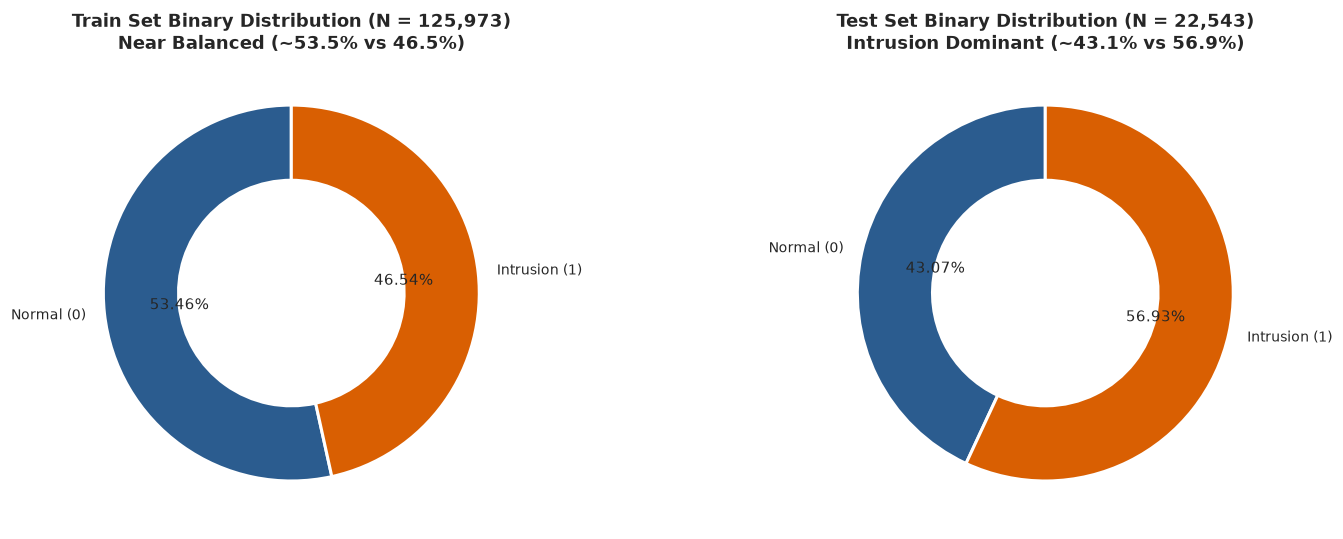

In [7]:
# Binary Class Distribution Computation
train_counts = train_df['is_intrusion'].value_counts()
train_pcts = train_df['is_intrusion'].value_counts(normalize=True) * 100

test_counts = test_df['is_intrusion'].value_counts()
test_pcts = test_df['is_intrusion'].value_counts(normalize=True) * 100

binary_class_df = pd.DataFrame({
    'Train Count': [train_counts[0], train_counts[1]],
    'Train Pct (%)': [f"{train_pcts[0]:.2f}%", f"{train_pcts[1]:.2f}%"],
    'Test Count': [test_counts[0], test_counts[1]],
    'Test Pct (%)': [f"{test_pcts[0]:.2f}%", f"{test_pcts[1]:.2f}%"]
}, index=['Normal (0)', 'Intrusion (1)'])

display(binary_class_df.style.set_caption("Table 5.1: Binary Class Breakdown in Train vs Test"))

# Imbalance Ratios
train_imb_ratio = train_counts[0] / train_counts[1]
test_imb_ratio = test_counts[1] / test_counts[0]
print(f"Train Normal-to-Intrusion Ratio: {train_imb_ratio:.2f} : 1")
print(f"Test Intrusion-to-Normal Ratio: {test_imb_ratio:.2f} : 1 (Class Inversion!)")

# Visualizations: Donut Charts & Bar Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = ['#2b5c8f', '#d95f02']

# Donut Train
axes[0].pie(
    train_counts, 
    labels=['Normal (0)', 'Intrusion (1)'], 
    autopct='%1.2f%%', 
    startangle=90, 
    colors=palette,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2, 'width': 0.4}
)
axes[0].set_title(f"Train Set Binary Distribution (N = {len(train_df):,})\nNear Balanced (~53.5% vs 46.5%)", fontweight='bold')

# Donut Test
axes[1].pie(
    [test_counts[0], test_counts[1]], 
    labels=['Normal (0)', 'Intrusion (1)'], 
    autopct='%1.2f%%', 
    startangle=90, 
    colors=palette,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2, 'width': 0.4}
)
axes[1].set_title(f"Test Set Binary Distribution (N = {len(test_df):,})\nIntrusion Dominant (~43.1% vs 56.9%)", fontweight='bold')

plt.tight_layout()
plt.show()


## 6. Attack Types & 5-Class Categorization

Network attacks in NSL-KDD fall into four canonical DARPA categories:
- **Denial of Service (DoS)**: Attempts to overwhelm computing or network resources, preventing legitimate users from accessing services (e.g. *Neptune, Smurf, Teardrop, Pod*).
- **Surveillance / Probe**: Attempts to gather information about network architecture, open ports, and operating system vulnerabilities to launch future intrusions (e.g. *Portsweep, IPsweep, Nmap, Satan*).
- **Remote to Local (R2L)**: An unauthorized external attacker sends packets to an internal machine without an account to gain local access (e.g. *Guess_passwd, Warezclient, Warezmaster, Imap*).
- **User to Root (U2R)**: An attacker who already possesses a local non-privileged user account exploits vulnerabilities (e.g. buffer overflows) to obtain root/administrative privileges (e.g. *Buffer_overflow, Loadmodule, Rootkit, Perl*).


,Train Count,Train Pct (%),Test Count,Test Pct (%)
attack_category,,,,
DoS,45927,36.460000,7458,33.080000
Normal,67343,53.460000,9710,43.070000
Probe,11656,9.250000,2421,10.740000
R2L,995,0.790000,2887,12.810000
U2R,52,0.040000,67,0.300000


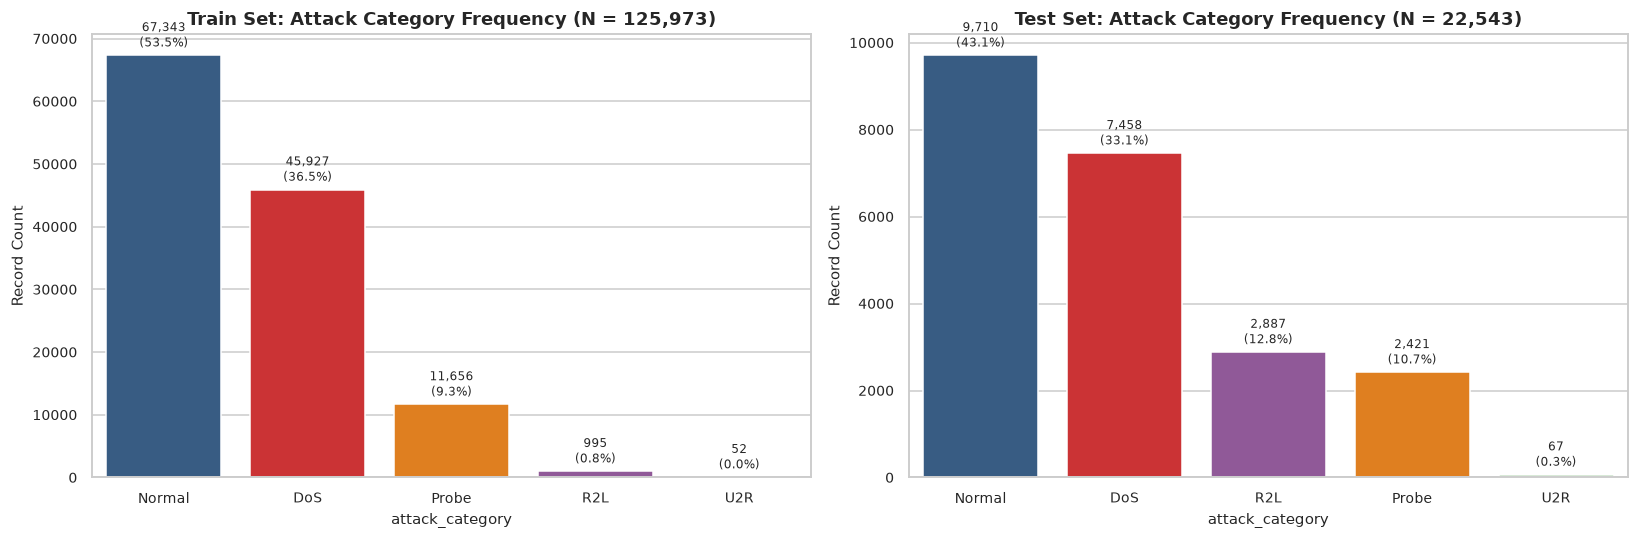

⚠️ Extreme Class Imbalance Warning:
  - In the Training Set, U2R accounts for only 52 instances (0.041%).
  - In the Training Set, R2L accounts for only 995 instances (0.790%).
  - DoS + Normal dominate 89.92% of the training dataset.


In [8]:
# 5-Class Attack Category Distributions
cat_train = train_df['attack_category'].value_counts()
cat_train_pct = train_df['attack_category'].value_counts(normalize=True) * 100

cat_test = test_df['attack_category'].value_counts()
cat_test_pct = test_df['attack_category'].value_counts(normalize=True) * 100

cat_df = pd.DataFrame({
    'Train Count': cat_train,
    'Train Pct (%)': cat_train_pct.round(2),
    'Test Count': cat_test,
    'Test Pct (%)': cat_test_pct.round(2)
}).fillna(0)

display(cat_df.style.set_caption("Table 6.1: 5-Class Attack Category Distribution in Train and Test"))

# Visualizing Category Breakdown
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cat_palette = {'Normal': '#2b5c8f', 'DoS': '#e41a1c', 'Probe': '#ff7f00', 'R2L': '#984ea3', 'U2R': '#4daf4a'}

sns.barplot(x=cat_train.index, y=cat_train.values, palette=cat_palette, ax=axes[0])
axes[0].set_title(f"Train Set: Attack Category Frequency (N = {len(train_df):,})", fontweight='bold')
axes[0].set_ylabel("Record Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(train_df)*100:.1f}%)",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points')

sns.barplot(x=cat_test.index, y=cat_test.values, palette=cat_palette, ax=axes[1])
axes[1].set_title(f"Test Set: Attack Category Frequency (N = {len(test_df):,})", fontweight='bold')
axes[1].set_ylabel("Record Count")
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(test_df)*100:.1f}%)",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

# Extreme minority class analysis
print(f"⚠️ Extreme Class Imbalance Warning:")
print(f"  - In the Training Set, U2R accounts for only {cat_train.get('U2R', 0)} instances ({cat_train_pct.get('U2R', 0):.3f}%).")
print(f"  - In the Training Set, R2L accounts for only {cat_train.get('R2L', 0)} instances ({cat_train_pct.get('R2L', 0):.3f}%).")
print(f"  - DoS + Normal dominate 89.92% of the training dataset.")


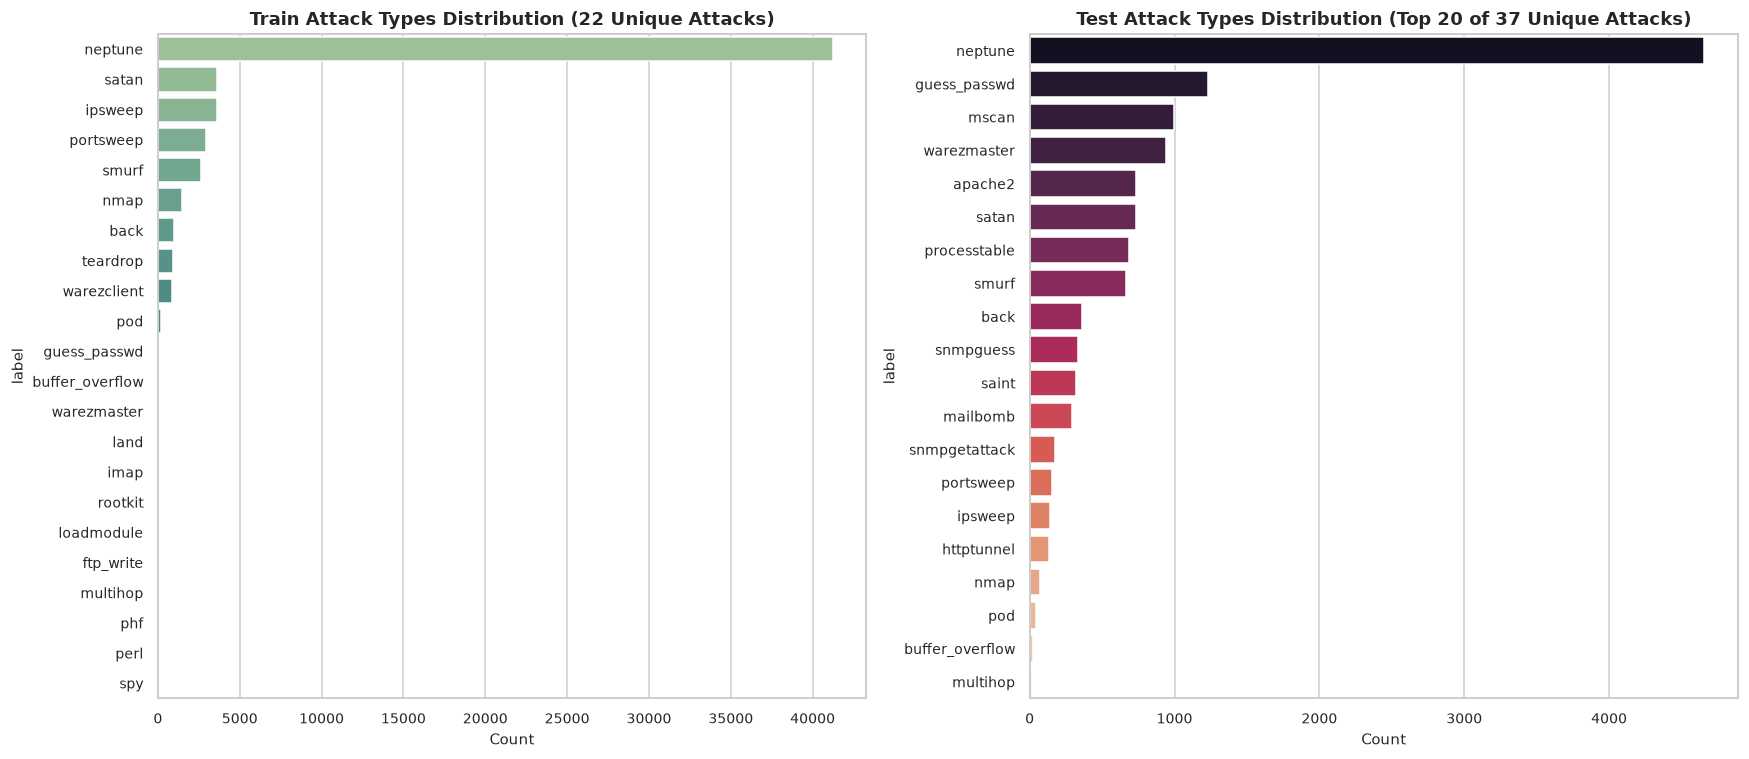

In [9]:
# Individual Attack Breakdown in Train and Test
train_attack_counts = train_df[train_df['label'] != 'normal']['label'].value_counts()
test_attack_counts = test_df[test_df['label'] != 'normal']['label'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(x=train_attack_counts.values, y=train_attack_counts.index, palette='crest', ax=axes[0])
axes[0].set_title(f"Train Attack Types Distribution ({len(train_attack_counts)} Unique Attacks)", fontweight='bold')
axes[0].set_xlabel("Count")

# Top 20 for test
sns.barplot(x=test_attack_counts.head(20).values, y=test_attack_counts.head(20).index, palette='rocket', ax=axes[1])
axes[1].set_title(f"Test Attack Types Distribution (Top 20 of {len(test_attack_counts)} Unique Attacks)", fontweight='bold')
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()


## 7. Novel / Zero-Day Attacks in the Test Set

A crucial property of the NSL-KDD benchmark is evaluating a classifier's capability to detect **novel zero-day attacks** that were completely unseen during training. 

The test set contains **17 new attack types** that never appeared in the training set.


In [10]:
# Identification & Quantification of Novel Zero-Day Attacks in Test Set
train_attacks = set(train_df['label'].unique()) - {'normal'}
test_attacks = set(test_df['label'].unique()) - {'normal'}

novel_attacks = test_attacks - train_attacks
novel_records = test_df[test_df['label'].isin(novel_attacks)]
novel_count = len(novel_records)

novel_summary = []
for atk in sorted(novel_attacks):
    count = (test_df['label'] == atk).sum()
    cat = ATTACK_MAPPING.get(atk, 'Unknown')
    novel_summary.append({
        'Novel Attack Name': atk,
        'DARPA Category': cat,
        'Test Count': count,
        '% of Test Attacks': f"{(count / len(test_df[test_df['label'] != 'normal'])) * 100:.2f}%",
        '% of Total Test Set': f"{(count / len(test_df)) * 100:.2f}%"
    })

novel_df = pd.DataFrame(novel_summary).sort_values('Test Count', ascending=False)
display(novel_df.style.hide(axis='index').set_caption(f"Table 7.1: The 17 Novel Attack Types in Test Set (Total Instances: {novel_count:,})"))

print(f"📊 Novel Attacks Summary:")
print(f"  - Total Novel Attack Types: {len(novel_attacks)}")
print(f"  - Total Novel Attack Records in Test: {novel_count:,} ({novel_count / len(test_df) * 100:.2f}% of entire test set!)")
print(f"  - Percentage of Test Attacks that are Novel: {novel_count / len(test_df[test_df['label'] != 'normal']) * 100:.2f}%")
print(f"  - Category Breakdown of Novel Attacks:")
print(novel_records['attack_category'].value_counts())


Novel Attack Name,DARPA Category,Test Count,% of Test Attacks,% of Total Test Set
mscan,Probe,996,7.76%,4.42%
apache2,DoS,737,5.74%,3.27%
processtable,DoS,685,5.34%,3.04%
snmpguess,R2L,331,2.58%,1.47%
saint,Probe,319,2.49%,1.42%
mailbomb,DoS,293,2.28%,1.30%
snmpgetattack,R2L,178,1.39%,0.79%
httptunnel,R2L,133,1.04%,0.59%
named,R2L,17,0.13%,0.08%
ps,U2R,15,0.12%,0.07%


📊 Novel Attacks Summary:
  - Total Novel Attack Types: 17
  - Total Novel Attack Records in Test: 3,750 (16.63% of entire test set!)
  - Percentage of Test Attacks that are Novel: 29.22%
  - Category Breakdown of Novel Attacks:
attack_category
DoS      1717
Probe    1315
R2L       688
U2R        30
Name: count, dtype: int64


## 8. Feature Distributions & Descriptive Statistics

We compute full parametric (mean, std) and non-parametric (median, IQR, min, max, skewness, kurtosis) descriptive statistics for all numerical features.


In [11]:
# Descriptive Statistical Profile of Numerical Features
num_cols = train_df.select_dtypes(include=[np.number]).columns.drop(['is_intrusion', 'difficulty_level'])

stats_records = []
for c in num_cols:
    series = train_df[c]
    q25 = series.quantile(0.25)
    q75 = series.quantile(0.75)
    iqr = q75 - q25
    stats_records.append({
        'Feature': c,
        'Mean': round(series.mean(), 4),
        'Std': round(series.std(), 4),
        'Min': series.min(),
        '25%': round(q25, 4),
        'Median': round(series.median(), 4),
        '75%': round(q75, 4),
        'Max': series.max(),
        'IQR': round(iqr, 4),
        'Skewness': round(series.skew(), 2),
        'Kurtosis': round(series.kurtosis(), 2)
    })

summary_stats_df = pd.DataFrame(stats_records).sort_values('Skewness', ascending=False)
display(summary_stats_df.head(15).style.hide(axis='index').set_caption("Table 8.1: Top 15 Highly Skewed Features"))


Feature,Mean,Std,Min,25%,Median,75%,Max,IQR,Skewness,Kurtosis
is_host_login,0.000000,0.002800,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,354.930000,125973.000000
dst_bytes,19779.114400,4021269.151400,0.000000,0.000000,0.000000,516.000000,1309937401.000000,516.000000,290.050000,90941.730000
num_compromised,0.279300,23.942000,0.000000,0.000000,0.000000,0.000000,7479.000000,0.000000,250.110000,75956.230000
num_root,0.302200,24.399600,0.000000,0.000000,0.000000,0.000000,7468.000000,0.000000,236.910000,70070.210000
src_bytes,45566.743000,5870331.181900,0.000000,0.000000,44.000000,276.000000,1379963888.000000,276.000000,190.670000,39354.120000
urgent,0.000100,0.014400,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000,149.910000,24967.320000
land,0.000200,0.014100,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,70.970000,5034.120000
num_shells,0.000400,0.022200,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,59.590000,3993.590000
num_file_creations,0.012700,0.483900,0.000000,0.000000,0.000000,0.000000,43.000000,0.000000,55.670000,3603.310000
num_failed_logins,0.001200,0.045200,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000,53.760000,3869.070000


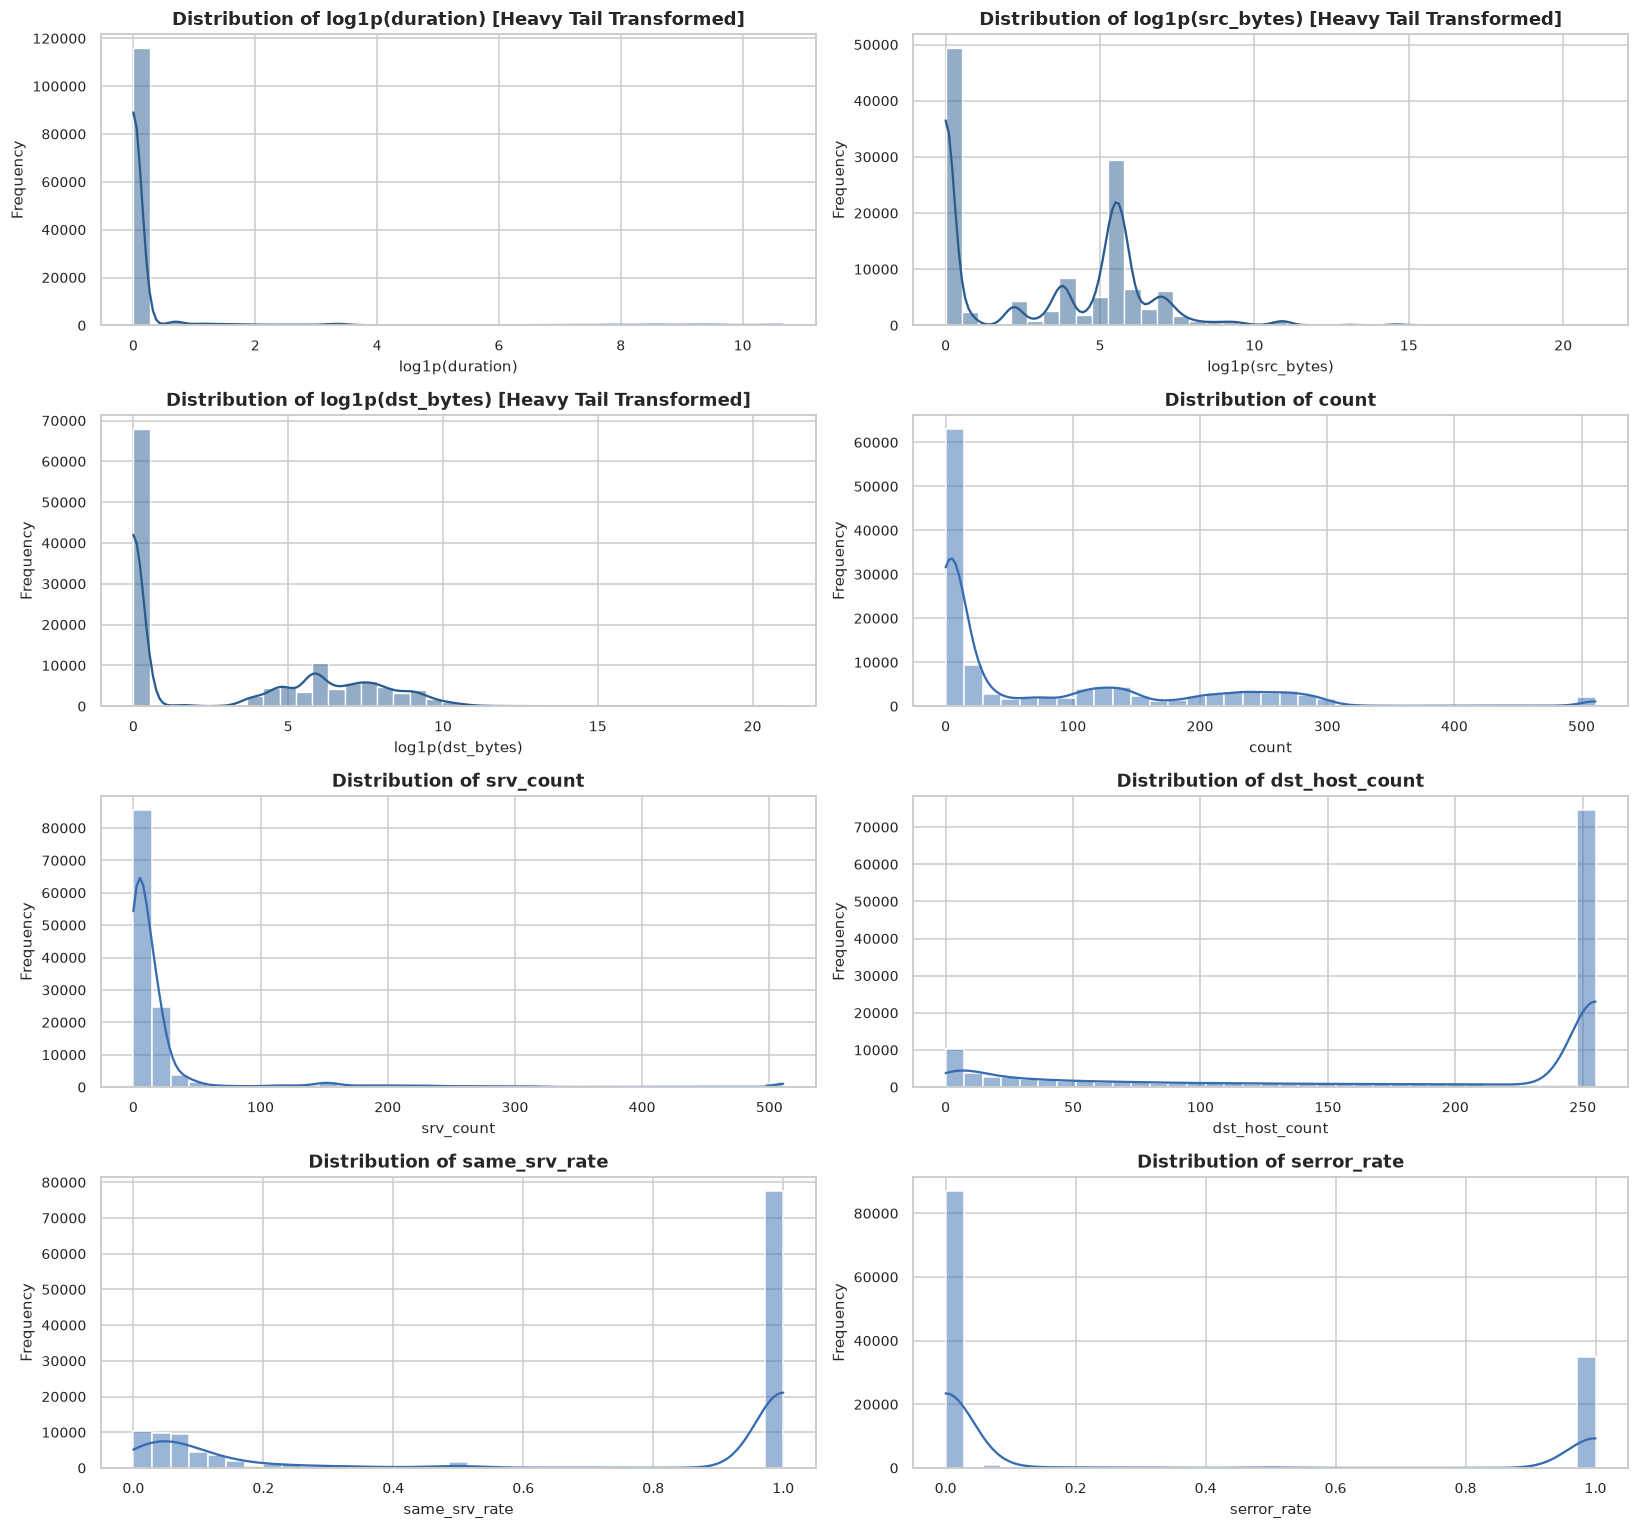

In [12]:
# Distribution Visualizations for Key Continuous Features
plot_features = ['duration', 'src_bytes', 'dst_bytes', 'count', 'srv_count', 'dst_host_count', 'same_srv_rate', 'serror_rate']

fig, axes = plt.subplots(4, 2, figsize=(15, 14))
axes = axes.flatten()

for i, col in enumerate(plot_features):
    ax = axes[i]
    if col in ['duration', 'src_bytes', 'dst_bytes']:
        # Apply log1p for heavy tailed byte features
        log_data = np.log1p(train_df[col])
        sns.histplot(log_data, kde=True, bins=40, color='#2b5c8f', ax=ax)
        ax.set_title(f"Distribution of log1p({col}) [Heavy Tail Transformed]", fontweight='bold')
        ax.set_xlabel(f"log1p({col})")
    else:
        sns.histplot(train_df[col], kde=True, bins=35, color='#386cb0', ax=ax)
        ax.set_title(f"Distribution of {col}", fontweight='bold')
        ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


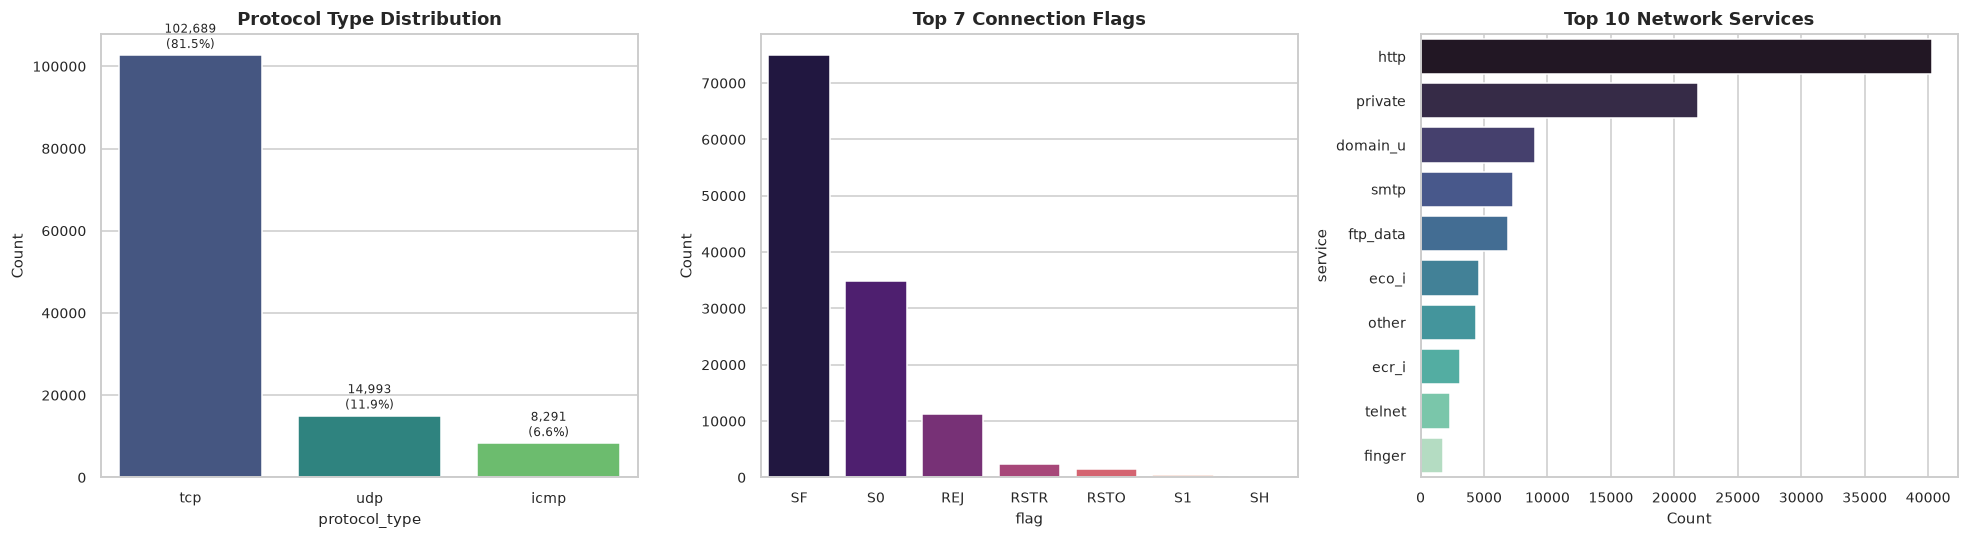

In [13]:
# Categorical Features Distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Protocol Type
sns.countplot(data=train_df, x='protocol_type', palette='viridis', ax=axes[0], order=train_df['protocol_type'].value_counts().index)
axes[0].set_title("Protocol Type Distribution", fontweight='bold')
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(train_df)*100:.1f}%)",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')

# Flag (Top 7)
top_flags = train_df['flag'].value_counts().head(7).index
sns.countplot(data=train_df[train_df['flag'].isin(top_flags)], x='flag', palette='magma', ax=axes[1], order=top_flags)
axes[1].set_title("Top 7 Connection Flags", fontweight='bold')
axes[1].set_ylabel("Count")

# Service (Top 10)
top_srv = train_df['service'].value_counts().head(10).index
sns.countplot(data=train_df[train_df['service'].isin(top_srv)], y='service', palette='mako', ax=axes[2], order=top_srv)
axes[2].set_title("Top 10 Network Services", fontweight='bold')
axes[2].set_xlabel("Count")

plt.tight_layout()
plt.show()


## 9. Feature vs Intrusion Detected: Pattern Analysis

We systematically address the critical question:
> **"Is there any pattern that on certain feature values intrusions occur?"**

We evaluate empirical conditional probabilities:
$$P(\\text{Intrusion} = 1 \\mid \\text{Feature} = x)$$
across protocol types, connection flags, network services, and continuous traffic rates.


,count,Attack Rate,Attack Rate (%)
protocol_type,,,
icmp,8291,0.842118,84.210000
tcp,102689,0.478036,47.800000
udp,14993,0.170680,17.070000


,count,Attack Rate,Attack Rate (%)
flag,,,
SF,74945,0.154140,15.410000
S0,34851,0.989842,98.980000
REJ,11233,0.760260,76.030000
RSTR,2421,0.939694,93.970000
RSTO,1562,0.859795,85.980000
S1,365,0.010959,1.100000
SH,271,0.992620,99.260000
S2,127,0.062992,6.300000


,count,Attack Rate
service,,
Z39_50,862,1.000000
uucp,780,1.000000
courier,734,1.000000
bgp,710,1.000000
whois,693,1.000000
uucp_path,689,1.000000
iso_tsap,687,1.000000
nnsp,630,1.000000
vmnet,617,1.000000


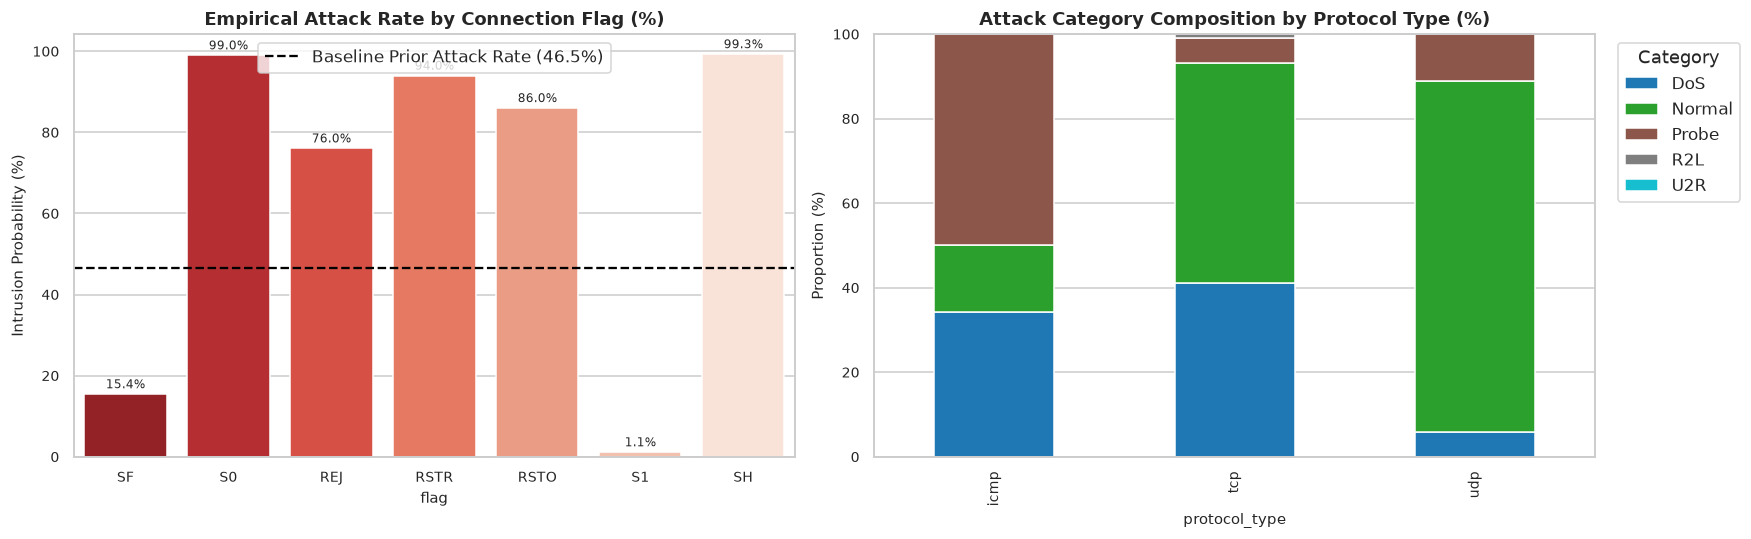

In [14]:
# Feature vs Intrusion Pattern Analysis

# 1. Protocol vs Intrusion
proto_attack = train_df.groupby('protocol_type')['is_intrusion'].agg(['count', 'mean']).rename(columns={'mean': 'Attack Rate'})
proto_attack['Attack Rate (%)'] = (proto_attack['Attack Rate'] * 100).round(2)
display(proto_attack.style.set_caption("Table 9.1: Attack Rate by Protocol Type"))

# 2. Connection Flag vs Intrusion
flag_attack = train_df.groupby('flag')['is_intrusion'].agg(['count', 'mean']).rename(columns={'mean': 'Attack Rate'}).sort_values('count', ascending=False)
flag_attack['Attack Rate (%)'] = (flag_attack['Attack Rate'] * 100).round(2)
display(flag_attack.head(8).style.set_caption("Table 9.2: Attack Rate by Connection Flag (Top 8)"))

# 3. High-Risk Services with 100% Attack Rate
srv_attack = train_df.groupby('service')['is_intrusion'].agg(['count', 'mean']).rename(columns={'mean': 'Attack Rate'})
srv_100 = srv_attack[(srv_attack['Attack Rate'] == 1.0) & (srv_attack['count'] > 100)].sort_values('count', ascending=False)
display(srv_100.style.set_caption("Table 9.3: Services with Guaranteed (100%) Intrusion Rate (Count > 100)"))

# Visualizing Conditional Attack Rates
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Flag Attack Rate Bar Plot
sns.barplot(x=flag_attack.head(7).index, y=flag_attack.head(7)['Attack Rate (%)'], palette='Reds_r', ax=axes[0])
axes[0].set_title("Empirical Attack Rate by Connection Flag (%)", fontweight='bold')
axes[0].set_ylabel("Intrusion Probability (%)")
axes[0].axhline(y=46.54, color='black', linestyle='--', label='Baseline Prior Attack Rate (46.5%)')
axes[0].legend()
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')

# Stacked Protocol Distribution by Category
proto_cat_ct = pd.crosstab(train_df['protocol_type'], train_df['attack_category'], normalize='index') * 100
proto_cat_ct.plot(kind='bar', stacked=True, colormap='tab10', ax=axes[1], edgecolor='white')
axes[1].set_title("Attack Category Composition by Protocol Type (%)", fontweight='bold')
axes[1].set_ylabel("Proportion (%)")
axes[1].legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()


Feature,Mutual Information,ANOVA F-Score
src_bytes,0.563749,0.761306
dst_bytes,0.439886,3.137808
diff_srv_rate,0.362617,1283.388727
same_srv_rate,0.354777,38725.894988
dst_host_srv_count,0.332071,32749.988443
dst_host_same_srv_rate,0.302491,27274.559649
logged_in,0.284073,27297.014708
dst_host_diff_srv_rate,0.283809,1802.591567
dst_host_serror_rate,0.281743,22183.361006
dst_host_srv_serror_rate,0.278728,22717.674309


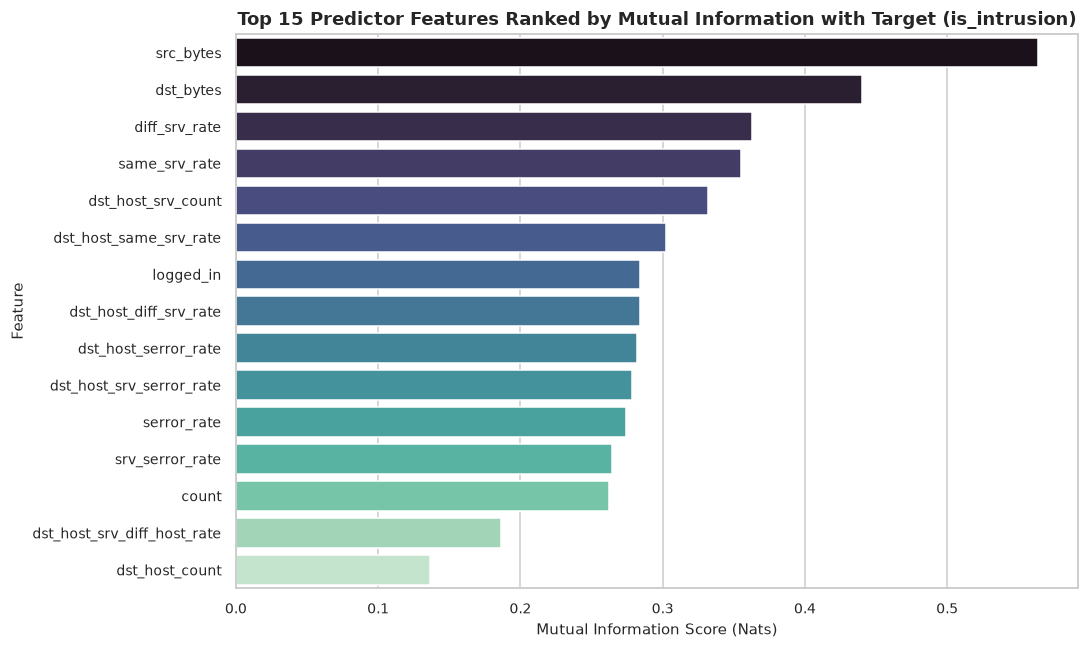

In [15]:
# Information Value & Discriminative Power Ranking (ANOVA F-Score & Mutual Info)
sample_train = train_df.sample(n=30000, random_state=42)
X_num_sample = sample_train[num_cols].fillna(0)
y_sample = sample_train['is_intrusion']

# ANOVA F-Value
f_scores, p_vals = f_classif(X_num_sample, y_sample)

# Mutual Information Score
mi_scores = mutual_info_classif(X_num_sample, y_sample, random_state=42)

ranking_df = pd.DataFrame({
    'Feature': num_cols,
    'Mutual Information': mi_scores,
    'ANOVA F-Score': f_scores
}).sort_values('Mutual Information', ascending=False)

display(ranking_df.head(15).style.hide(axis='index').set_caption("Table 9.4: Top 15 Most Discriminative Features by Mutual Information"))

# Visualization of Top 15 Features by Mutual Information
plt.figure(figsize=(10, 6))
sns.barplot(x='Mutual Information', y='Feature', data=ranking_df.head(15), palette='mako')
plt.title("Top 15 Predictor Features Ranked by Mutual Information with Target (is_intrusion)", fontweight='bold')
plt.xlabel("Mutual Information Score (Nats)")
plt.tight_layout()
plt.show()


## 10. Zero & Near-Zero Variance Analysis

Features with zero variance (constant across all samples) provide zero information gain to any machine learning algorithm and can cause singular matrix errors in linear models. Near-zero variance features (where one value represents >99.9% of samples) provide negligible utility.


In [16]:
# Zero & Near-Zero Variance Detection
variances = train_df[num_cols].var()

variance_records = []
for c in num_cols:
    val_counts = train_df[c].value_counts(normalize=True)
    top_freq = val_counts.iloc[0] * 100
    top_val = val_counts.index[0]
    variance_records.append({
        'Feature': c,
        'Variance': variances[c],
        'Most Frequent Value': top_val,
        'Dominance (% of Samples)': round(top_freq, 3),
        'Unique Values': train_df[c].nunique(),
        'Status': 'Zero Variance (Constant)' if variances[c] == 0 else ('Near-Zero Variance' if top_freq > 99.9 else 'Adequate Variance')
    })

var_df = pd.DataFrame(variance_records).sort_values('Variance')
zero_var_df = var_df[var_df['Status'].isin(['Zero Variance (Constant)', 'Near-Zero Variance'])]
display(zero_var_df.style.hide(axis='index').set_caption("Table 10.1: Features with Zero or Near-Zero Variance"))

print(f"🛑 Zero-Variance Constant Feature Identified: 'num_outbound_cmds' has variance 0.00 across all 125,973 train records and 22,543 test records.")
print(f"💡 Actionable Recommendation for Notebook 02: Drop 'num_outbound_cmds' during preprocessing.")


Feature,Variance,Most Frequent Value,Dominance (% of Samples),Unique Values,Status
num_outbound_cmds,0.000000,0.000000,100.000000,1,Zero Variance (Constant)
is_host_login,0.000008,0.000000,99.999000,2,Near-Zero Variance
land,0.000198,0.000000,99.980000,2,Near-Zero Variance
urgent,0.000206,0.000000,99.993000,4,Near-Zero Variance
num_shells,0.000492,0.000000,99.963000,3,Near-Zero Variance
su_attempted,0.002039,0.000000,99.936000,3,Near-Zero Variance
num_failed_logins,0.002047,0.000000,99.903000,6,Near-Zero Variance


🛑 Zero-Variance Constant Feature Identified: 'num_outbound_cmds' has variance 0.00 across all 125,973 train records and 22,543 test records.
💡 Actionable Recommendation for Notebook 02: Drop 'num_outbound_cmds' during preprocessing.


## 11. Correlation Matrix & Multicollinearity Analysis

Multicollinearity occurs when independent features are highly correlated with each other ($|r| > 0.80$). This distorts regression coefficients in linear models (such as Logistic Regression in Notebook 04), making standard errors unreliably large.


Feature (Strongest Negative),Negative Correlation,Feature (Strongest Positive),Positive Correlation
same_srv_rate,-0.751900,dst_host_srv_serror_rate,0.655000
dst_host_srv_count,-0.722500,dst_host_serror_rate,0.651800
dst_host_same_srv_rate,-0.693800,serror_rate,0.650700
logged_in,-0.690200,srv_serror_rate,0.648300
srv_diff_host_rate,-0.119400,count,0.576400
is_guest_login,-0.039300,dst_host_count,0.375100
num_access_files,-0.036700,srv_rerror_rate,0.253500
su_attempted,-0.022400,dst_host_srv_rerror_rate,0.253400


Feature 1,Feature 2,|Pearson r|
num_compromised,num_root,0.998800
serror_rate,srv_serror_rate,0.993300
rerror_rate,srv_rerror_rate,0.989000
srv_serror_rate,dst_host_srv_serror_rate,0.986300
dst_host_serror_rate,dst_host_srv_serror_rate,0.985100
serror_rate,dst_host_srv_serror_rate,0.981100
serror_rate,dst_host_serror_rate,0.979400
srv_serror_rate,dst_host_serror_rate,0.977600
srv_rerror_rate,dst_host_srv_rerror_rate,0.970200
rerror_rate,dst_host_srv_rerror_rate,0.964400


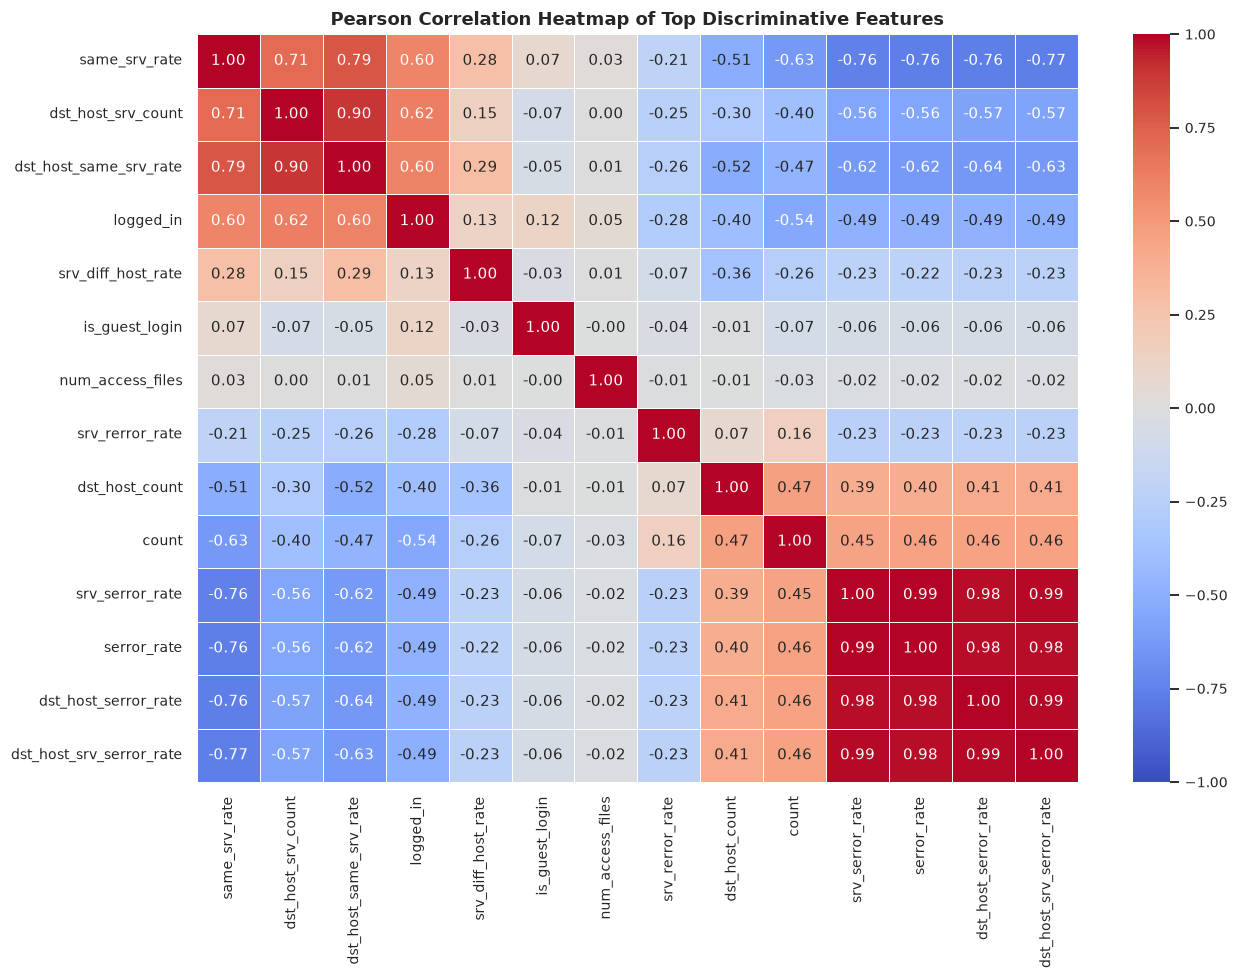

In [17]:
# Correlation Matrix & Multicollinearity Analysis
active_num_cols = [c for c in num_cols if c != 'num_outbound_cmds']
corr_matrix = train_df[active_num_cols].corr()

# Correlation with Target
target_corr = train_df[active_num_cols].corrwith(train_df['is_intrusion']).sort_values()

# Display Top Negative and Positive Correlations with Target
target_corr_df = pd.DataFrame({
    'Feature (Strongest Negative)': target_corr.head(8).index,
    'Negative Correlation': target_corr.head(8).values.round(4),
    'Feature (Strongest Positive)': target_corr.tail(8).iloc[::-1].index,
    'Positive Correlation': target_corr.tail(8).iloc[::-1].values.round(4)
})
display(target_corr_df.style.hide(axis='index').set_caption("Table 11.1: Features with Strongest Correlation to is_intrusion"))

# Identify Highly Collinear Pairs (|r| > 0.80)
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = []
for c in upper_tri.columns:
    for r in upper_tri.index:
        val = upper_tri.loc[r, c]
        if abs(val) > 0.80:
            high_corr_pairs.append({'Feature 1': r, 'Feature 2': c, '|Pearson r|': round(abs(val), 4)})

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values('|Pearson r|', ascending=False)
display(high_corr_df.style.hide(axis='index').set_caption("Table 11.2: Collinear Feature Pairs with |r| > 0.80"))

# Correlation Heatmap for Top Features
top_corr_features = list(target_corr.head(7).index) + list(target_corr.tail(7).index)
plt.figure(figsize=(12, 9))
sns.heatmap(train_df[top_corr_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Pearson Correlation Heatmap of Top Discriminative Features", fontweight='bold')
plt.tight_layout()
plt.show()


## 12. Boxplots & Visual Feature Separation

We inspect boxplots of the top continuous features partitioned by binary target (`Normal` vs `Intrusion`) and across the five attack categories.


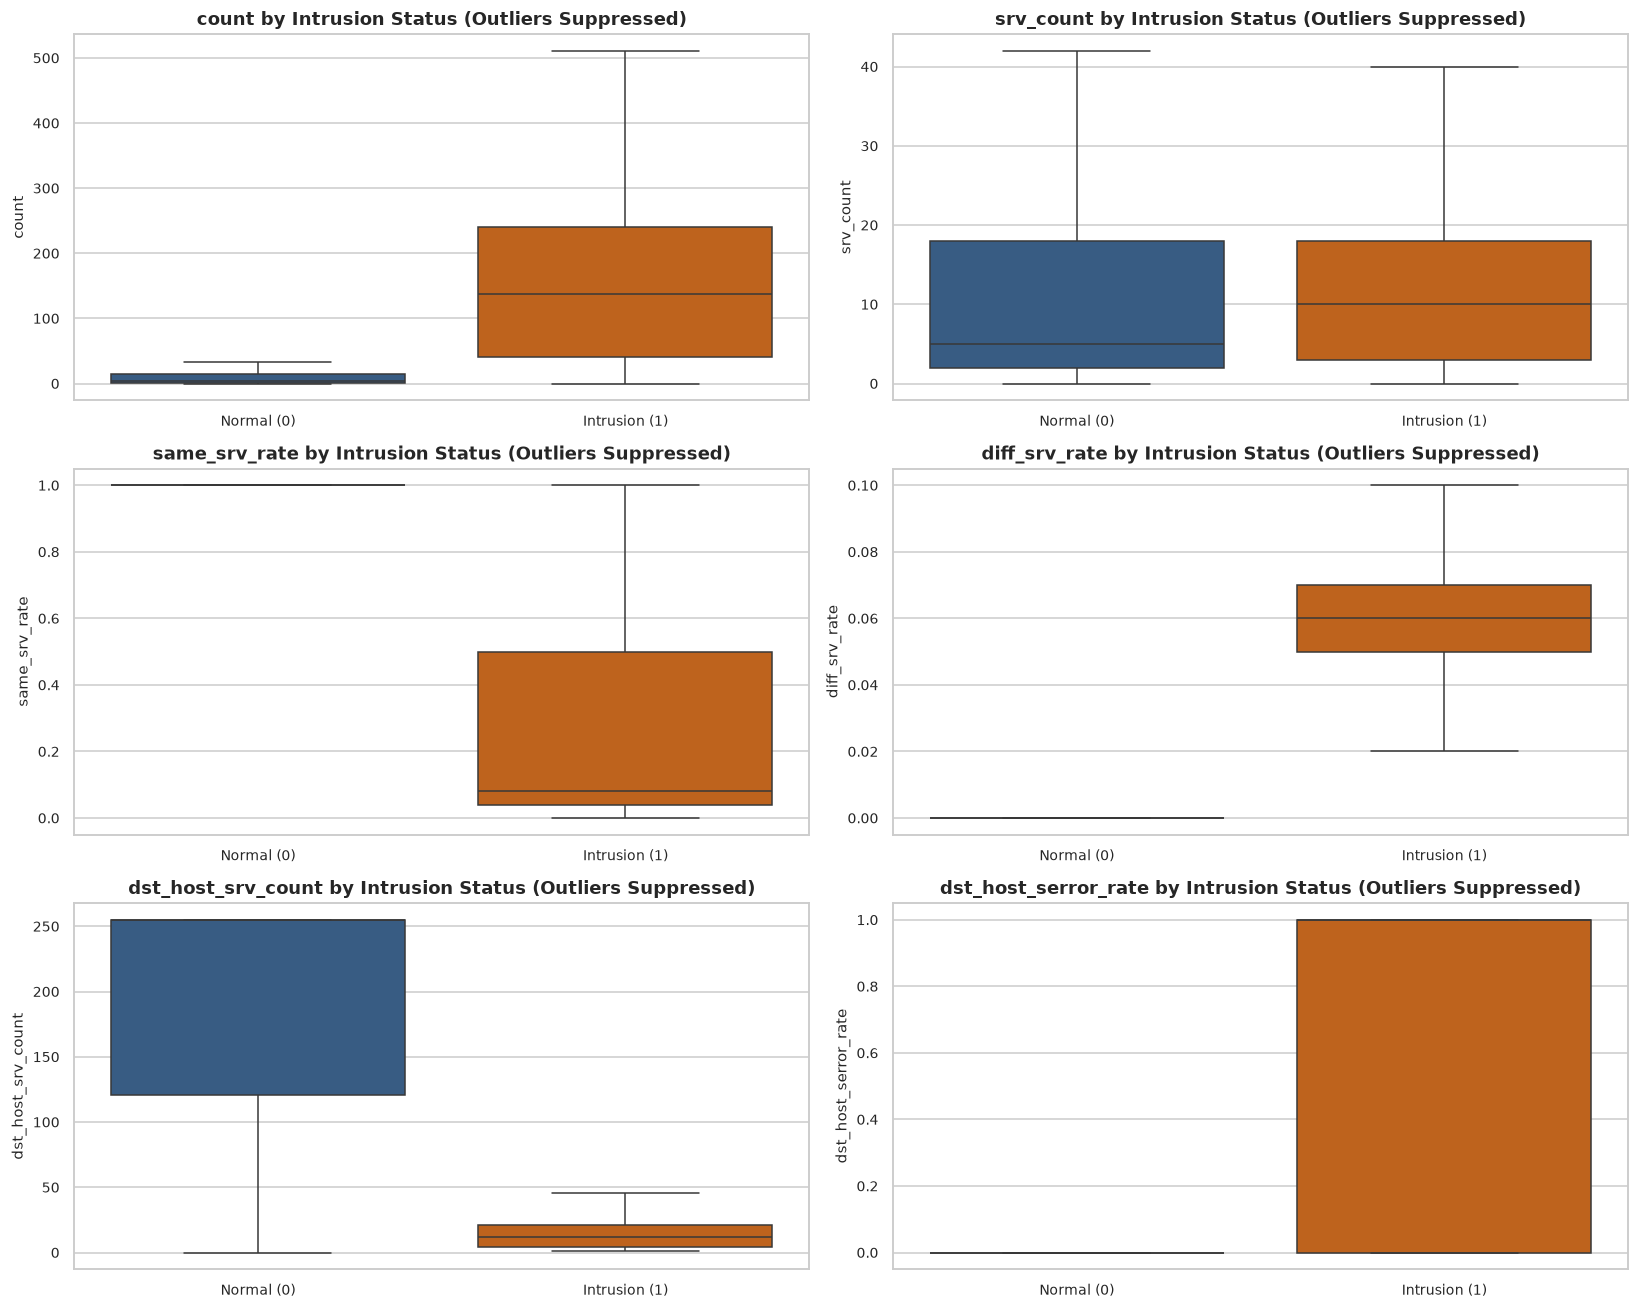

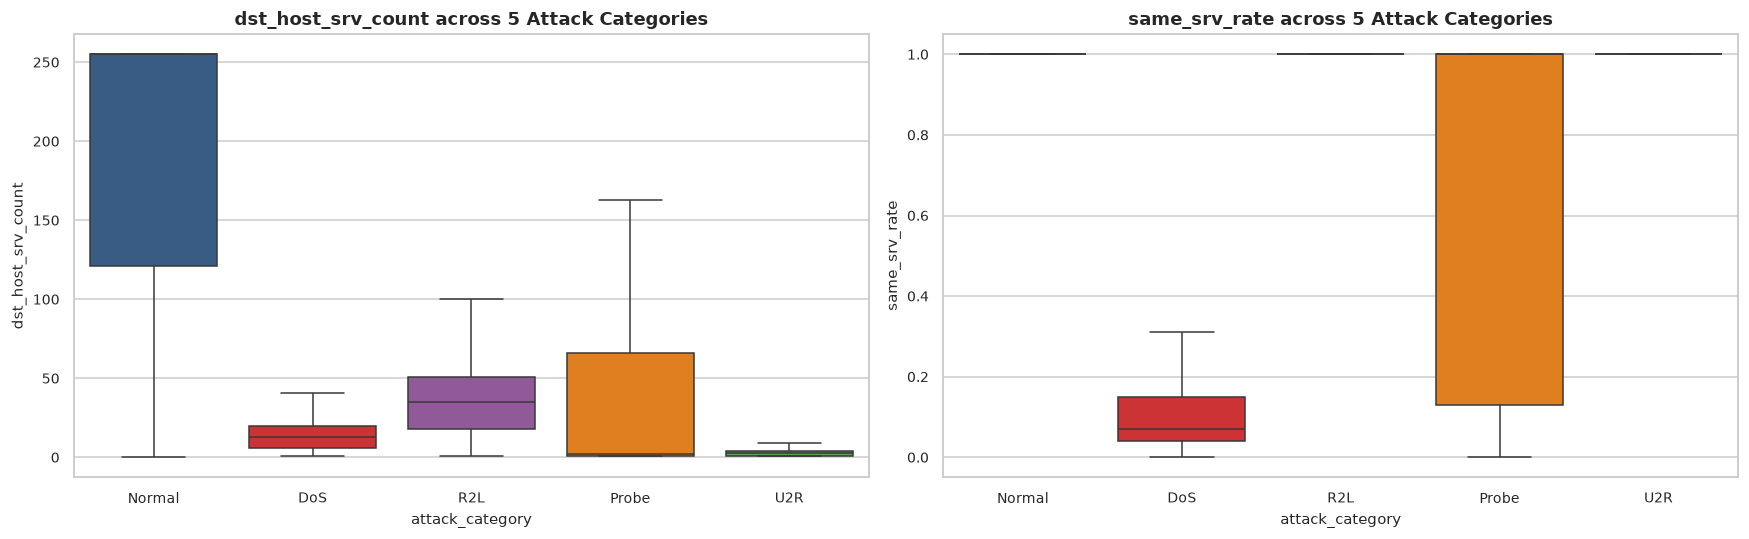

In [18]:
# Boxplots of Key Features across Target Classes
box_features = ['count', 'srv_count', 'same_srv_rate', 'diff_srv_rate', 'dst_host_srv_count', 'dst_host_serror_rate']

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(box_features):
    ax = axes[i]
    sns.boxplot(data=train_df, x='is_intrusion', y=col, palette=['#2b5c8f', '#d95f02'], ax=ax, showfliers=False)
    ax.set_title(f"{col} by Intrusion Status (Outliers Suppressed)", fontweight='bold')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Normal (0)', 'Intrusion (1)'])
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

# Boxplot Across 5 Attack Categories for dst_host_srv_count and same_srv_rate
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=train_df, x='attack_category', y='dst_host_srv_count', palette=cat_palette, ax=axes[0], showfliers=False)
axes[0].set_title("dst_host_srv_count across 5 Attack Categories", fontweight='bold')

sns.boxplot(data=train_df, x='attack_category', y='same_srv_rate', palette=cat_palette, ax=axes[1], showfliers=False)
axes[1].set_title("same_srv_rate across 5 Attack Categories", fontweight='bold')

plt.tight_layout()
plt.show()


## 13. Outliers & Extreme Value Analysis

In cybersecurity telemetry, "outliers" are rarely sensor malfunctions. They often represent legitimate high-intensity cyber activities:
- Volumetric DoS floods (extreme connection `count` and byte rates).
- Large data exfiltration (massive `src_bytes`).
- Long-lived persistent backdoor connections (extreme `duration`).

We quantify outliers using the standard Interquartile Range (IQR) method:
$$\\text{Outliers} = \\{x \\mid x < Q_1 - 1.5 \\times \\text{IQR} \\quad \\text{or} \\quad x > Q_3 + 1.5 \\times \\text{IQR}\\}$$


In [19]:
# Outlier Quantification & Extreme Values
outlier_list = []
for col in active_num_cols:
    s = train_df[col]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_b = q1 - 1.5 * iqr
    upper_b = q3 + 1.5 * iqr
    outlier_mask = (s < lower_b) | (s > upper_b)
    outlier_count = outlier_mask.sum()
    outlier_pct = (outlier_count / len(train_df)) * 100
    outlier_list.append({
        'Feature': col,
        'Min': s.min(),
        'Max': s.max(),
        'Skewness': round(s.skew(), 2),
        'Outlier Count': outlier_count,
        'Outlier Pct (%)': round(outlier_pct, 2)
    })

outlier_df = pd.DataFrame(outlier_list).sort_values('Outlier Pct (%)', ascending=False)
display(outlier_df.head(12).style.hide(axis='index').set_caption("Table 13.1: Top Features with Highest Outlier Percentages"))

# Extreme Value Investigation
print("Extreme Maximums in Network Telemetry:")
for feat in ['src_bytes', 'dst_bytes', 'duration', 'num_compromised']:
    max_val = train_df[feat].max()
    mean_val = train_df[feat].mean()
    ratio = max_val / (mean_val + 1e-5)
    print(f"  - {feat:16s}: Max = {max_val:>12,d} | Mean = {mean_val:>10.2f} | Max/Mean Ratio = {ratio:>10.1f}x")

print("\n💡 Critical Cybersecurity Domain Conclusion:")
print("  - DO NOT DROP OUTLIERS! In intrusion detection, high-volume outliers are the exact footprint of DoS and exfiltration.")
print("  - Preprocessing Recommendation: Apply monotonic compression (log1p) or RobustScaler (using median & IQR).")


Feature,Min,Max,Skewness,Outlier Count,Outlier Pct (%)
srv_diff_host_rate,0.000000,1.000000,2.860000,28399,22.540000
dst_host_same_src_port_rate,0.000000,1.000000,2.090000,25052,19.890000
dst_bytes,0.000000,1309937401.000000,290.050000,23579,18.720000
dst_host_rerror_rate,0.000000,1.000000,2.350000,22795,18.100000
dst_host_srv_rerror_rate,0.000000,1.000000,2.340000,19357,15.370000
srv_rerror_rate,0.000000,1.000000,2.330000,16206,12.860000
rerror_rate,0.000000,1.000000,2.330000,16190,12.850000
src_bytes,0.000000,1379963888.000000,190.670000,13840,10.990000
srv_count,0.000000,511.000000,4.690000,12054,9.570000
dst_host_srv_diff_host_rate,0.000000,1.000000,5.550000,11682,9.270000


Extreme Maximums in Network Telemetry:
  - src_bytes       : Max = 1,379,963,888 | Mean =   45566.74 | Max/Mean Ratio =    30284.5x
  - dst_bytes       : Max = 1,309,937,401 | Mean =   19779.11 | Max/Mean Ratio =    66228.3x
  - duration        : Max =       42,908 | Mean =     287.14 | Max/Mean Ratio =      149.4x
  - num_compromised : Max =        7,479 | Mean =       0.28 | Max/Mean Ratio =    26781.5x

💡 Critical Cybersecurity Domain Conclusion:
  - DO NOT DROP OUTLIERS! In intrusion detection, high-volume outliers are the exact footprint of DoS and exfiltration.
  - Preprocessing Recommendation: Apply monotonic compression (log1p) or RobustScaler (using median & IQR).


## 14. Data Leakage & Difficulty Score Evaluation

We evaluate three potential sources of data leakage:
1. **Target / Metadata Leakage via `difficulty_level` (Column 42)**:
   In the 2009 NSL-KDD foundational paper, Tavallaee et al. evaluated 21 distinct machine learning classifiers on KDD Cup 99. The `difficulty_level` (0–21) represents the number of those 21 models that correctly predicted the connection.
   - It is a **meta-attribute produced post-hoc by ML algorithms**, NOT a network traffic property.
   - Feeding `difficulty_level` into predictive models would cause catastrophic target leakage.
2. **Train-Test Feature Overlap**: 654 feature vectors exist in both Train and Test.
3. **Covariate Shift**: Distribution divergence between Train and Test sets.


,count,mean,std,min,25%,50%,75%,max
is_intrusion,,,,,,,,
0,67343.000000,20.315920,1.482986,1.000000,20.000000,21.000000,21.000000,21.000000
1,58630.000000,18.571550,2.670144,0.000000,18.000000,19.000000,20.000000,21.000000


,count,mean,std,min,25%,50%,75%,max
is_intrusion,,,,,,,,
0,9710.000000,19.962616,2.861327,0.000000,21.000000,21.000000,21.000000,21.000000
1,12833.000000,16.547495,4.561434,0.000000,14.000000,18.000000,20.000000,21.000000


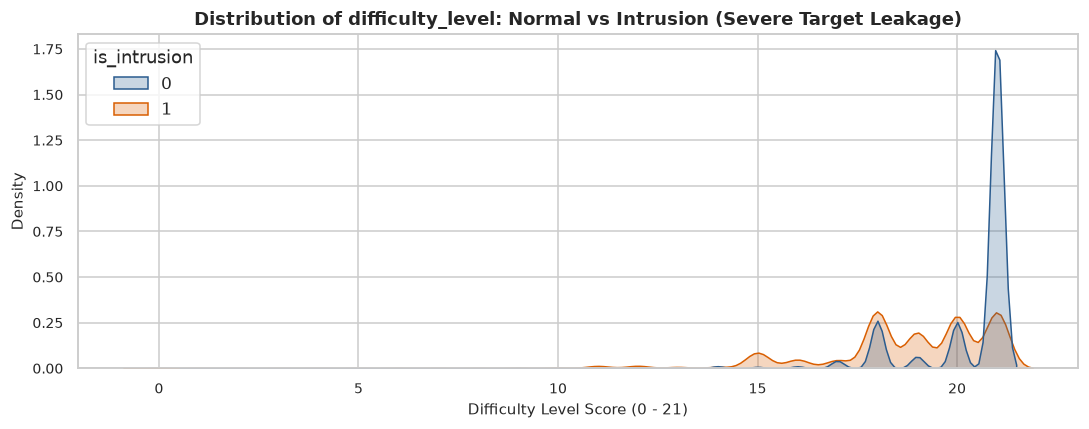

🛑 STRICT PREPROCESSING RULE:
  - 'difficulty_level' MUST be dropped from all feature matrices before training.
  - It can only be used as an auxiliary evaluation metric to analyze model performance across difficulty strata.


In [20]:
# Target Leakage Audit of difficulty_level
diff_summary = train_df.groupby('is_intrusion')['difficulty_level'].describe()
display(diff_summary.style.set_caption("Table 14.1: Difficulty Level Distribution for Normal vs Intrusion in Train"))

diff_test_summary = test_df.groupby('is_intrusion')['difficulty_level'].describe()
display(diff_test_summary.style.set_caption("Table 14.2: Difficulty Level Distribution for Normal vs Intrusion in Test"))

# Visualizing difficulty_level distribution
plt.figure(figsize=(10, 4))
sns.kdeplot(data=train_df, x='difficulty_level', hue='is_intrusion', common_norm=False, palette=['#2b5c8f', '#d95f02'], fill=True)
plt.title("Distribution of difficulty_level: Normal vs Intrusion (Severe Target Leakage)", fontweight='bold')
plt.xlabel("Difficulty Level Score (0 - 21)")
plt.tight_layout()
plt.show()

print("🛑 STRICT PREPROCESSING RULE:")
print("  - 'difficulty_level' MUST be dropped from all feature matrices before training.")
print("  - It can only be used as an auxiliary evaluation metric to analyze model performance across difficulty strata.")


## 15. Actionable Roadmap for Preprocessing & Modeling Pipeline

Based on our empirical EDA findings, we establish a concrete, step-by-step engineering roadmap for the subsequent project notebooks:

| EDA Finding | Cybersecurity & Statistical Impact | Action in `02_preprocessing.ipynb` & Modeling |
| :--- | :--- | :--- |
| **Zero Variance Feature** | `num_outbound_cmds` is constant `0.0` for all 148,516 rows | **Drop `num_outbound_cmds`** completely from the feature set. |
| **Metadata Target Leakage** | `difficulty_level` is a post-hoc classifier consensus score | **Exclude `difficulty_level`** from training matrices ($X$). |
| **Categorical Predictors** | `protocol_type` (3), `flag` (11), `service` (70 unique values) | Apply **One-Hot Encoding** with `handle_unknown='ignore'` to support unseen test categories. |
| **Extreme Power-Law Tails** | `src_bytes` (skew=190.7), `dst_bytes` (skew=290.1), `duration` | Apply **`np.log1p()` transformation** or `RobustScaler` to stabilize gradients and variance. |
| **Severe Multicollinearity** | $r > 0.98$ between pairs (`serror_rate` & `srv_serror_rate`, etc.) | Address in **`04_logistic_regression.ipynb`** using L2/L1 regularization; tree models handle naturally. |
| **Extreme Class Imbalance** | U2R ($0.04\%$) and R2L ($0.79\%$) in training set | Use **`class_weight='balanced'`** or **SMOTE** oversampling for multi-class classifiers. |
| **17 Novel Attack Types** | 3,750 novel attack instances ($16.6\%$ of test set) | Primary benchmark metric must be **Recall on Novel Attacks** and **Macro F1-Score**, not raw Accuracy. |
| **Missing Values Clean** | $0$ nulls, $0$ NaNs, $0$ infinite values | No imputation step required, saving compute and avoiding artificial variance. |

---

### End-to-End Pipeline Roadmap:
1. `notebooks/01_data_exploration.ipynb` *(Current Notebook)*: Comprehensive EDA & data quality audit.
2. `notebooks/02_preprocessing.ipynb`: Pipeline construction (encoder, scaler, transformer, train/test split).
3. `notebooks/03_majority_baseline.ipynb`: Baseline zero-rule classifier establishing performance floor.
4. `notebooks/04_logistic_regression.ipynb`: Linear decision boundary benchmark with regularization.
5. `notebooks/05_decision_tree.ipynb`: Interpretable decision tree with rule extraction.
6. `notebooks/06_random_forest.ipynb`: Robust non-linear ensemble with feature importance ranking.
7. `notebooks/07_evaluation_comparison.ipynb`: Multi-model comparative evaluation on standard vs zero-day attacks.
